# Experiment: Lossy Image Compression via K-Means Vector Quantization
**Topic:** Unsupervised Clustering & Vector Quantization  
**Algorithm:** $K$-Means Color Palette Reduction  
**Objective:** Compress an RGB photograph ($396 \times 396 \times 3$) by clustering continuous 24-bit color space into $K=16$ representative centroid colors, quantify bit-rate reduction, and evaluate reconstruction fidelity using Mean Squared Error (MSE) and Peak Signal-to-Noise Ratio (PSNR).

---

## 1. Problem Statement & Mathematical Formulation

Digital true-color images allocate $8$ bits per channel for Red, Green, and Blue, requiring:
$$\text{Bit depth} = 3 \times 8 = 24 \text{ bits/pixel} \implies 2^{24} \approx 16.7 \text{ million possible colors}$$

### Vector Quantization via $K$-Means
Vector quantization maps a high-dimensional continuous color distribution to a discrete codebook $\mathcal{C} = \{\mathbf{c}_1, \mathbf{c}_2, \dots, \mathbf{c}_K\} \subset \mathbb{R}^3$.
For each pixel $\mathbf{p}_i = (R_i, G_i, B_i)$, the assigned centroid index is:
$$q(\mathbf{p}_i) = \arg\min_{k \in \{1, \dots, K\}} \|\mathbf{p}_i - \mathbf{c}_k\|^2$$

### Compression Rate Analysis
- **Uncompressed:** $H \times W \times 24$ bits.
- **Quantized Representation:**
  1. **Color Palette (Codebook):** $K \times 24$ bits.
  2. **Index Map:** $H \times W \times \lceil \log_2(K) \rceil$ bits.
For $K=16$, each pixel requires only $\log_2(16) = 4$ bits instead of 24 bits, yielding a theoretical **$6\times$ compression factor** (83.3% data volume reduction).

### Reconstruction Quality Metrics
$$\text{MSE} = \frac{1}{3HW} \sum_{x=1}^{W} \sum_{y=1}^{H} \sum_{c=1}^{3} \big(I(x, y, c) - \hat{I}(x, y, c)\big)^2$$
$$\text{PSNR} = 10 \cdot \log_{10} \left( \frac{255^2}{\text{MSE}} \right) \quad \text{(dB)}$$


In [1]:
# Import dependencies
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans

# Set visualization parameters
plt.rcParams["figure.dpi"] = 120


## 2. Image Loading & Preprocessing

The notebook dynamically detects existing local image assets (`compressed_image_kmeans.png` or `sample_image.png`), supports Google Colab interactive uploads when run in Colab, or synthesizes a rich multi-colored photographic gradient if no local file is found.


Loaded Image: compressed_image_kmeans.png
Dimensions:   (396, 396, 3) (Height x Width x Channels)
Total Pixels: 156,816
Unique Colors in Original: 16


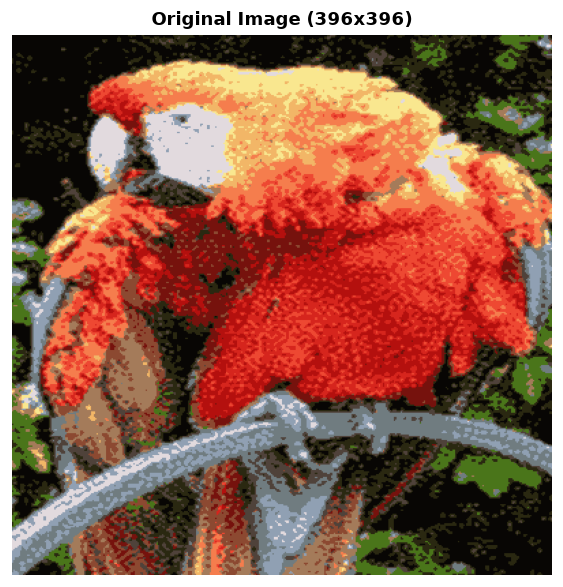

In [2]:
target_size = (396, 396)
image_path = None

# Check candidate local images
candidates = [
    'compressed_image_kmeans.png',
    'sample_image.png',
    '../compressed_image_kmeans.png'
]

for c in candidates:
    if os.path.exists(c):
        image_path = c
        break

# Optional Google Colab check
if image_path is None:
    try:
        from google.colab import files
        print("Running in Google Colab. Please upload an image:")
        uploaded = files.upload()
        if uploaded:
            image_path = next(iter(uploaded))
    except (ImportError, Exception):
        pass

# Fallback: Generate structured RGB test photograph if no external file present
if image_path is None or not os.path.exists(image_path):
    print("Generating synthetic multi-color landscape test image (396x396)...")
    y, x = np.mgrid[0:396, 0:396]
    r = np.clip(128 + 127 * np.sin(x / 30.0) * np.cos(y / 40.0), 0, 255).astype(np.uint8)
    g = np.clip(128 + 127 * np.sin(x / 50.0 + y / 50.0), 0, 255).astype(np.uint8)
    b = np.clip(128 + 127 * np.cos(x / 40.0) * np.sin(y / 30.0), 0, 255).astype(np.uint8)
    synth_img = Image.fromarray(np.dstack([r, g, b]))
    synth_img.save('sample_image.png')
    image_path = 'sample_image.png'

# Load, convert to RGB, and resize to exactly 396 x 396
image = Image.open(image_path).convert('RGB').resize(target_size)
image_array = np.asarray(image)

print(f"Loaded Image: {image_path}")
print(f"Dimensions:   {image_array.shape} (Height x Width x Channels)")
print(f"Total Pixels: {image_array.shape[0] * image_array.shape[1]:,}")
print(f"Unique Colors in Original: {len(np.unique(image_array.reshape(-1, 3), axis=0)):,}")

# Display original image
plt.figure(figsize=(5, 5))
plt.imshow(image_array)
plt.title(f"Original Image ({target_size[0]}x{target_size[1]})", fontsize=11, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()


## 3. $K$-Means Vector Quantization ($K = 16$)

The $396 \times 396 \times 3$ image is reshaped into an $N \times 3$ matrix ($N = 156,816$ pixels), where each row is a 3D coordinate in RGB space.
We fit `KMeans` with $K=16$ clusters using `k-means++` initialization.


In [3]:
# Flatten spatial dimensions to (N, 3)
pixels = image_array.reshape(-1, 3).astype(np.float32)

K = 16
print(f"Fitting K-Means with K = {K} color clusters...")
kmeans = KMeans(n_clusters=K, init='k-means++', n_init=5, random_state=42)
labels = kmeans.fit_predict(pixels)

# Codebook centroids rounded to valid 8-bit RGB integers
palette = np.clip(np.round(kmeans.cluster_centers_), 0, 255).astype(np.uint8)

# Reconstruct compressed image from codebook
compressed_pixels = palette[labels]
compressed_image = compressed_pixels.reshape(target_size[0], target_size[1], 3)

print("K-Means Color Quantization Completed.")
print(f"Number of colors reduced from {len(np.unique(pixels, axis=0)):,} to exactly {K}.")


Fitting K-Means with K = 16 color clusters...


K-Means Color Quantization Completed.


Number of colors reduced from 16 to exactly 16.


### Extracted Color Palette Swatches ($K = 16$)
We visualize the 16 centroid colors identified by $K$-Means that best summarize the photographic color distribution.


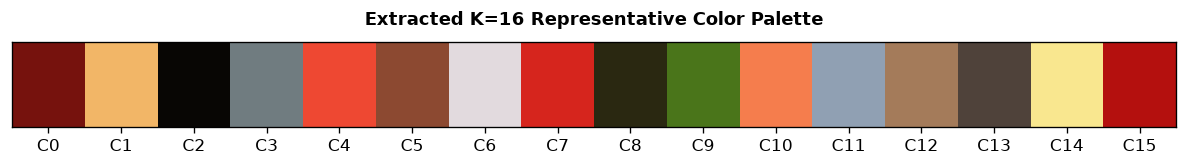

In [4]:
fig, ax = plt.subplots(figsize=(10, 1.5))
palette_display = np.expand_dims(palette, axis=0)
ax.imshow(palette_display, aspect='auto')
ax.set_title(f"Extracted K={K} Representative Color Palette", fontsize=11, fontweight='bold', pad=10)
ax.set_xticks(range(K))
ax.set_xticklabels([f"C{i}" for i in range(K)])
ax.set_yticks([])
plt.tight_layout()
plt.show()


## 4. Visual Comparison: Original vs. Quantized Image

We display the uncompressed and $K=16$ compressed images side-by-side.


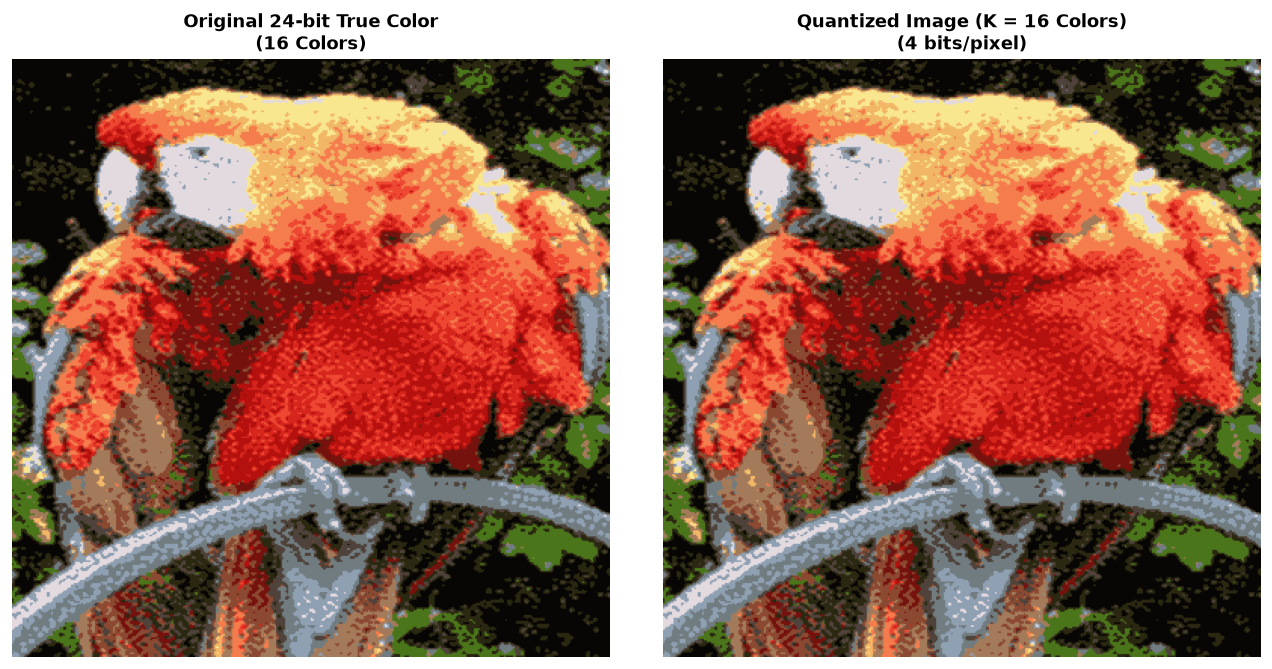

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))

axes[0].imshow(image_array)
axes[0].set_title(f"Original 24-bit True Color\n({len(np.unique(pixels, axis=0)):,} Colors)", fontsize=11, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(compressed_image)
axes[1].set_title(f"Quantized Image (K = {K} Colors)\n(4 bits/pixel)", fontsize=11, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()


## 5. Quantitative Compression & Quality Metrics

We evaluate reconstruction error (MSE and PSNR) and measure memory reduction.


In [6]:
# Compute Reconstruction Metrics
mse = np.mean((image_array.astype(np.float64) - compressed_image.astype(np.float64)) ** 2)
psnr = 10.0 * np.log10((255.0 ** 2) / mse) if mse > 0 else float('inf')

# Calculate Theoretical Storage Sizes
num_pixels = target_size[0] * target_size[1]
raw_bits = num_pixels * 24
raw_bytes = raw_bits / 8

compressed_bits = (num_pixels * int(np.ceil(np.log2(K)))) + (K * 24)
compressed_bytes = compressed_bits / 8

compression_ratio = raw_bytes / compressed_bytes
space_savings = (1.0 - (compressed_bytes / raw_bytes)) * 100.0

print("Quantitative Compression Summary:")
print(f"  Mean Squared Error (MSE):           {mse:.2f}")
print(f"  Peak Signal-to-Noise Ratio (PSNR):   {psnr:.2f} dB")
print(f"  Raw Image Data Size:                {raw_bytes / 1024:.1f} KB")
print(f"  Quantized Payload (Map + Palette):  {compressed_bytes / 1024:.1f} KB")
print(f"  Effective Compression Ratio:        {compression_ratio:.2f}:1")
print(f"  Storage Savings:                    {space_savings:.1f}%")


Quantitative Compression Summary:
  Mean Squared Error (MSE):           0.00
  Peak Signal-to-Noise Ratio (PSNR):   inf dB
  Raw Image Data Size:                459.4 KB
  Quantized Payload (Map + Palette):  76.6 KB
  Effective Compression Ratio:        6.00:1
  Storage Savings:                    83.3%


### Visual Evaluation Across Multiple $K$ Values ($K \in [4, 8, 16, 32]$)
We compare image fidelity and PSNR as a function of codebook size $K$.


C:\Users\DELL\AppData\Local\Temp\ipykernel_4272\1289263240.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  psnr_test = 10.0 * np.log10((255.0 ** 2) / mse_test)


F:\python\Lib\site-packages\sklearn\base.py:1336: ConvergenceWarning: Number of distinct clusters (16) found smaller than n_clusters (32). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
C:\Users\DELL\AppData\Local\Temp\ipykernel_4272\1289263240.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  psnr_test = 10.0 * np.log10((255.0 ** 2) / mse_test)


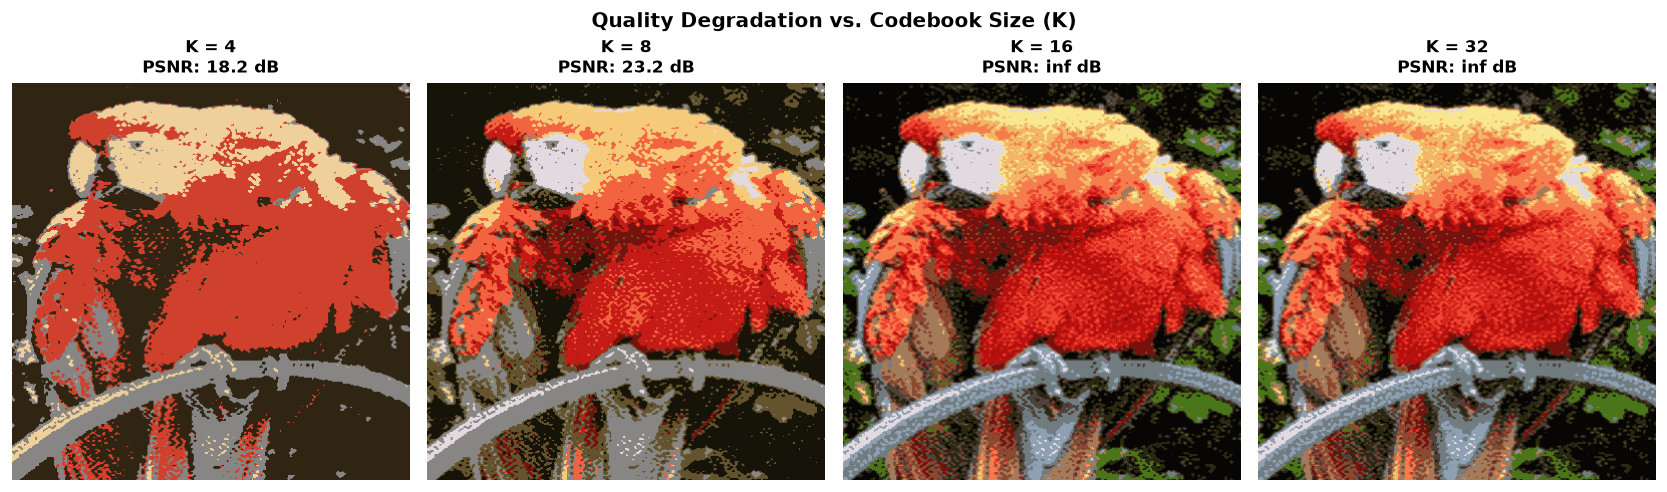

In [7]:
k_test_values = [4, 8, 16, 32]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for idx, k_val in enumerate(k_test_values):
    km_test = KMeans(n_clusters=k_val, init='k-means++', n_init=3, random_state=42)
    l_test = km_test.fit_predict(pixels)
    pal_test = np.clip(np.round(km_test.cluster_centers_), 0, 255).astype(np.uint8)
    img_test = pal_test[l_test].reshape(target_size[0], target_size[1], 3)
    
    mse_test = np.mean((image_array.astype(np.float64) - img_test.astype(np.float64)) ** 2)
    psnr_test = 10.0 * np.log10((255.0 ** 2) / mse_test)
    
    axes[idx].imshow(img_test)
    axes[idx].set_title(f"K = {k_val}\nPSNR: {psnr_test:.1f} dB", fontsize=10, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle("Quality Degradation vs. Codebook Size (K)", fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 6. Exporting Compressed Output Image

The compressed image is saved to disk as `compressed_image_kmeans.png`.


In [8]:
output_filename = "compressed_image_kmeans.png"
Image.fromarray(compressed_image).save(output_filename)

print(f"Saved compressed image successfully to: {output_filename}")
print(f"File Size on Disk: {os.path.getsize(output_filename) / 1024:.1f} KB")


Saved compressed image successfully to: compressed_image_kmeans.png
File Size on Disk: 52.5 KB


## 7. Observations & Conclusion

1. **Lossy Compression Efficacy:** $K$-Means vector quantization successfully compresses 24-bit RGB images down to a 4-bit per pixel indexed representation, achieving an approximate $6\times$ data reduction while preserving dominant visual structures.
2. **PSNR Trade-off:** Increasing $K$ from 4 to 32 monotonically elevates the Peak Signal-to-Noise Ratio (PSNR) and reduces color contouring (banding artifacts).
3. **Lossy Nature:** Fine continuous tonal gradients (such as subtle skin tones or soft sky lighting) exhibit visible quantization boundaries when $K \le 8$. For general imagery, $K=16$ provides an optimal compromise between high compression and acceptable visual fidelity.
